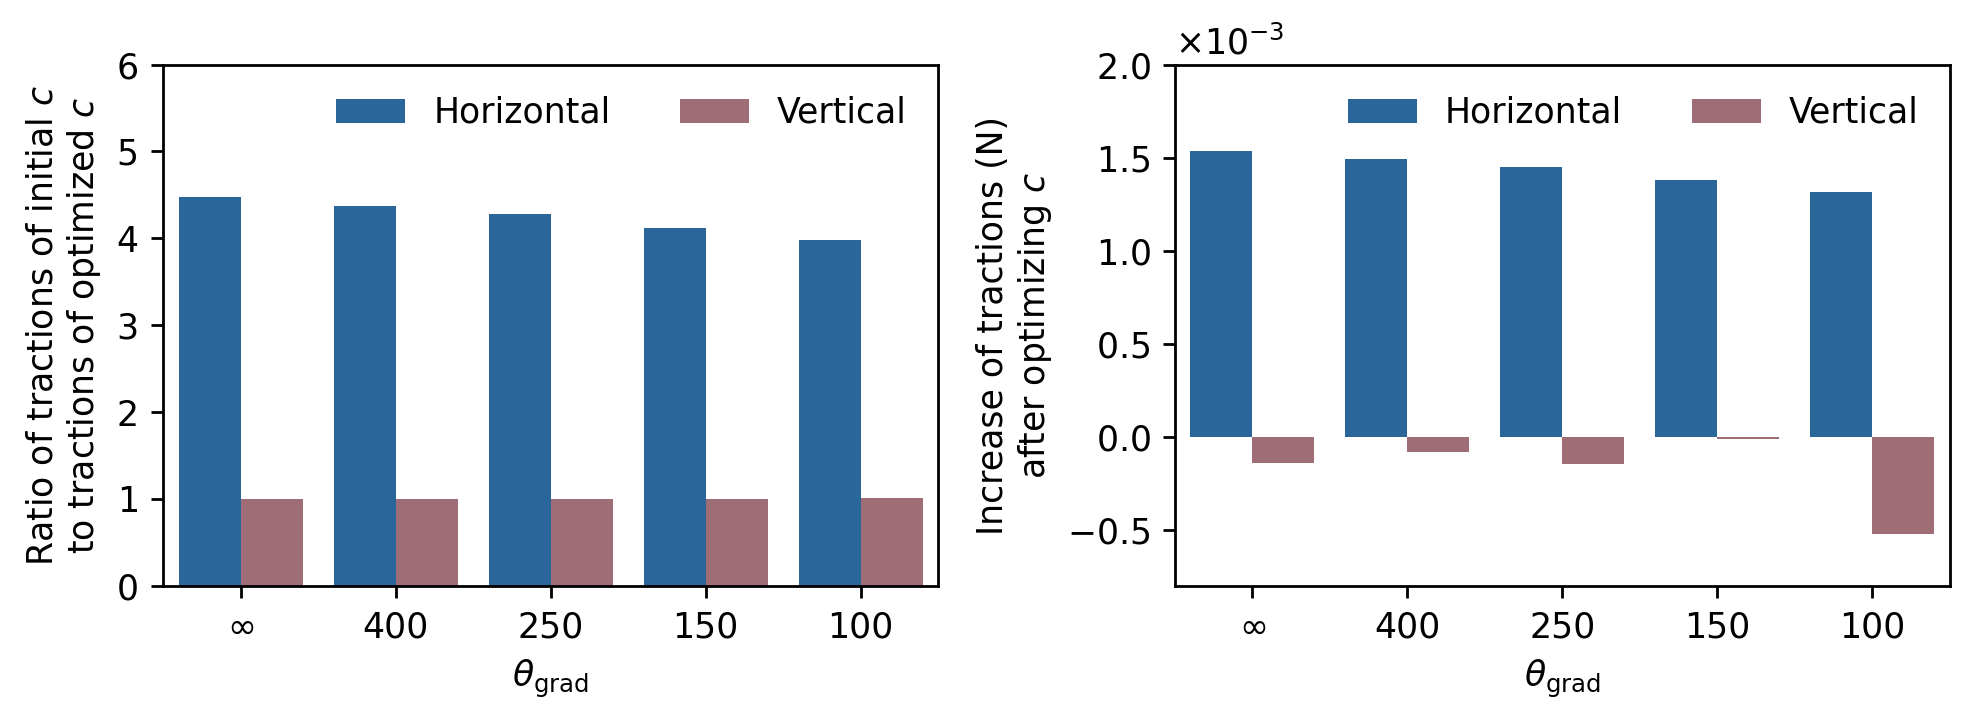

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

thres_paths = {
    r"$\infty$": "../../outputs/trapezoid-2025-11-04-12-48-35-nothres/records.csv",
    400: "../../outputs/trapezoid-2025-11-10-22-57-55-thres400/records.csv",
    250: "../../outputs/trapezoid-2025-11-11-10-19-47-thres250/records.csv",
    150: "../../outputs/trapezoid-2025-11-10-22-57-39-thres150/records.csv",
    100: "../../outputs/trapezoid-2025-11-10-22-57-32-thres100/records.csv",
}

dfs = {
    key: pd.read_csv(val) for key, val in thres_paths.items()
}

dfs_processed = {
    key: pd.DataFrame({"thres": [key, key], "type": ["Horizontal", "Vertical"], "value": [val["top_x"].values[-1]/val["top_x"].values[0], val["top_y"].values[-1]/val["top_y"].values[0]], "abs_increase": [-(val["top_x"].values[-1]-val["top_x"].values[0]), val["top_y"].values[-1]-val["top_y"].values[0]]}) for key, val in dfs.items()
}

# df0 = pd.DataFrame({"thres": [r"$\infty$", r"$\infty$"], "type": ["Horizontal", "Vertical"], "value": [4.4746086710, 1.0030866765], "abs_increase": [-0.00044155236656244067+0.001975774048110545, -0.04617517159117138+0.046317699407743024]})
# df100 = pd.DataFrame({"thres": [100, 100], "type": ["Horizontal", "Vertical"], "value": [4.1952650275, 1.0090849388], "abs_increase": [-0.0004415523665624409+0.001852429201234409,-0.04617517159117152+0.04659467019985208]})
# df150 = pd.DataFrame({"thres": [150, 150], "type": ["Horizontal", "Vertical"], "value": [4.3007660425, 1.0054187229], "abs_increase": [-0.00044155236656243915+0.0018990134240865898, -0.046175171591171724+0.046425382048636]})
# df200 = pd.DataFrame({"thres": [200, 200], "type": ["Horizontal", "Vertical"], "value": [4.3527237154, 1.0043960853], "abs_increase": [-0.0004415523665624422+0.0019219554575148512, -0.04617517159117185+0.04637816158613137]})
# df400 = pd.DataFrame({"thres": [400, 400], "type": ["Horizontal", "Vertical"], "value": [4.4298379222, 1.0026589808], "abs_increase": [-0.00044155236656244165+0.0019560054180213925, -0.04617517159117164+0.046297950484724536]})

df = pd.concat(dfs_processed.values())

import seaborn as sns

plt.figure(figsize=(8,3.0), dpi=250)
ax = plt.subplot(121)
sns.barplot(data=df, x="thres", y="value", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
ax.set_ylim([0, 6])
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax.legend(handles=handles, labels=labels, title=False, frameon=False, ncol=2)
ax.set_xlabel(r"$\theta_{\text{grad}}$")
ax.set_ylabel("Ratio of tractions of initial $c$\nto tractions of optimized $c$")

ax = plt.subplot(122)
sns.barplot(data=df, x="thres", y="abs_increase", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax.legend(handles=handles, labels=labels, title=False, frameon=False, loc="upper right", ncol=2)
ax.set_xlabel(r"$\theta_{\text{grad}}$")
ax.set_ylabel("Increase of tractions (N)\nafter optimizing $c$")
ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0), useMathText=True)
ax.set_ylim([-0.8e-3, 2e-3])

plt.tight_layout()
plt.savefig("trapezoid_threshold_traction_diff.pdf", bbox_inches="tight")
plt.show()
plt.close()

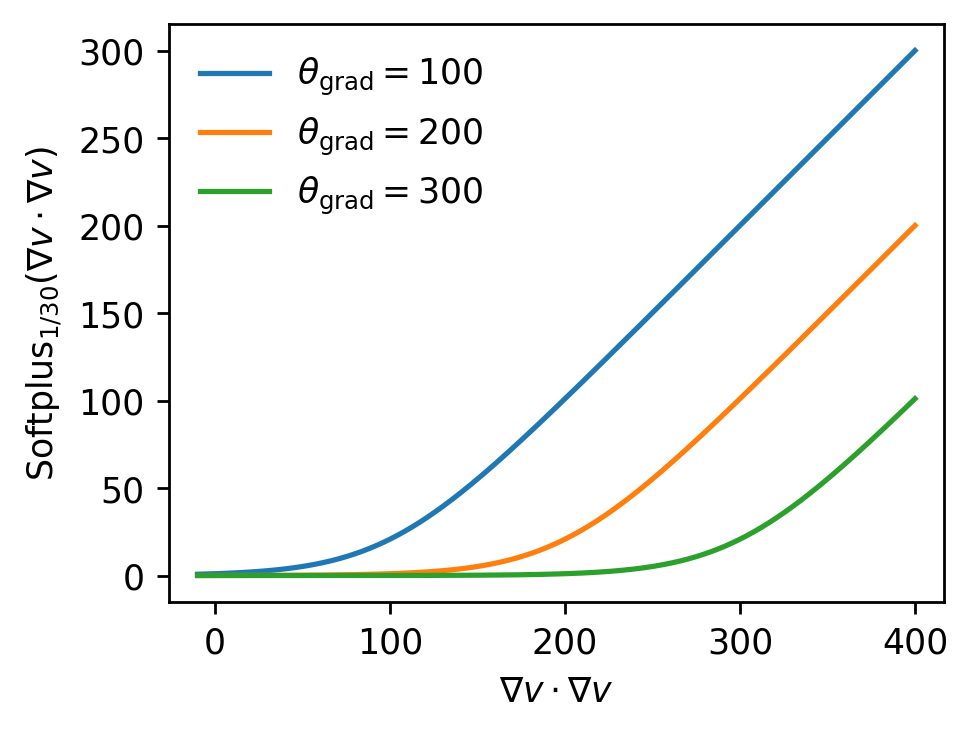

In [13]:
import matplotlib.pyplot as plt
import numpy as np
thres = 100
smoothness = 30
softplus = lambda x, thres: np.log(1 + np.exp((x-thres) / smoothness)) * smoothness

x = np.linspace(-10, 400, 1000)

plt.figure(figsize=(4,3), dpi=250)
plt.plot(x, softplus(x, 100), label=r"$\theta_{\text{grad}}=100$")
plt.plot(x, softplus(x, 200), label=r"$\theta_{\text{grad}}=200$")
plt.plot(x, softplus(x, 300), label=r"$\theta_{\text{grad}}=300$")
plt.ylabel(r"$\mathrm{Softplus}_{1/30}(\nabla v\cdot \nabla v)$")
plt.xlabel(r"$\nabla v\cdot \nabla v$")
plt.legend(frameon=False)
plt.axis("equal")
plt.show()
plt.close()